# BlinkIT Grocery Sales Analysis
**Domain:** Retail & Grocery Sales Analytics | **Company:** Sapphire IQ
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

This notebook follows the four objectives of the Sapphire IQ project brief:
1. Understand the business and its sales performance
2. Make sure the available information is reliable
3. Find out what is driving better sales performance
4. Help management make better business decisions

> Run it with **Kernel -> Restart Kernel and Run All Cells**. Keep `BlinkIT Grocery Data.xlsx` in the same folder as this notebook.

## Setup: import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_excel("BlinkIT Grocery Data.xlsx")
df.columns = [str(c).strip() for c in df.columns]
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.10,15.10,145.48,5.00
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.01,11.80,115.35,5.00
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.03,13.85,165.02,5.00
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.04,12.15,126.50,5.00
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.03,19.60,55.16,5.00


# Objective 1: Understand the business and its sales performance

### Task 1.1 - 1.2: What products, outlets and locations are there?

In [2]:
df.info()
print()
print("Item types      :", df["Item Type"].nunique())
print("Unique items    :", df["Item Identifier"].nunique())
print("Outlets         :", df["Outlet Identifier"].nunique())
print("Outlet types    :", df["Outlet Type"].unique().tolist())
print("Location tiers  :", df["Outlet Location Type"].unique().tolist())
print("Outlet sizes    :", df["Outlet Size"].unique().tolist())

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB

Item types      : 16
Unique items    : 1559
Outlets        

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Outlet Establishment Year,"8,523.00","2,016.45",3.19,"2,011.00","2,014.00","2,016.00","2,018.00","2,022.00"
Item Visibility,"8,523.00",0.07,0.05,0.00,0.03,0.05,0.09,0.33
Item Weight,"7,060.00",12.86,4.64,4.55,8.77,12.60,16.85,21.35
Sales,"8,523.00",140.99,62.28,31.29,93.83,143.01,185.64,266.89
Rating,"8,523.00",3.97,0.61,1.00,4.00,4.00,4.20,5.00


# Objective 2: Make sure the information is reliable

### Task 2.1: Missing values

In [4]:
missing = df.isna().sum().to_frame("Missing")
missing["Percent"] = missing["Missing"] / len(df) * 100
display(missing[missing["Missing"] > 0] if (missing["Missing"] > 0).any() else missing)

# Where are the missing weights?
print("\nOutlets with missing Item Weight:")
print(df[df["Item Weight"].isna()]["Outlet Identifier"].value_counts())

,Missing,Percent
Item Weight,1463,17.17



Outlets with missing Item Weight:
Outlet Identifier
OUT027    935
OUT019    528
Name: count, dtype: int64


**Finding:** only `Item Weight` has missing values (about 17%). They all come from two outlets (**OUT019** and **OUT027**), so the gap is a *recording problem at those outlets*, not random. We do **not** invent values. Weight is left blank and Pandas skips it automatically in calculations.

### Task 2.2: Duplicate records

In [5]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


### Task 2.4: Make similar information look the same

In [6]:
print("Fat content labels BEFORE cleaning:")
print(df["Item Fat Content"].value_counts())

clean = df.drop_duplicates().copy()
for col in ["Item Fat Content", "Item Type", "Outlet Identifier",
            "Outlet Location Type", "Outlet Size", "Outlet Type"]:
    clean[col] = clean[col].astype("string").str.strip()

clean["Item Fat Content"] = clean["Item Fat Content"].replace(
    {"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular", "regular": "Regular"})

print("\nFat content labels AFTER cleaning:")
print(clean["Item Fat Content"].value_counts())

Fat content labels BEFORE cleaning:
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Fat content labels AFTER cleaning:
Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: Int64


### Task 2.3: Unusually high or low values (outliers)

,Column,Lower limit,Upper limit,Outliers,Percent
0,Sales,-43.90,323.37,0,0.00
1,Item Visibility,-0.07,0.20,144,1.69
2,Item Weight,-3.34,28.96,0,0.00
3,Rating,3.70,4.50,1931,22.66


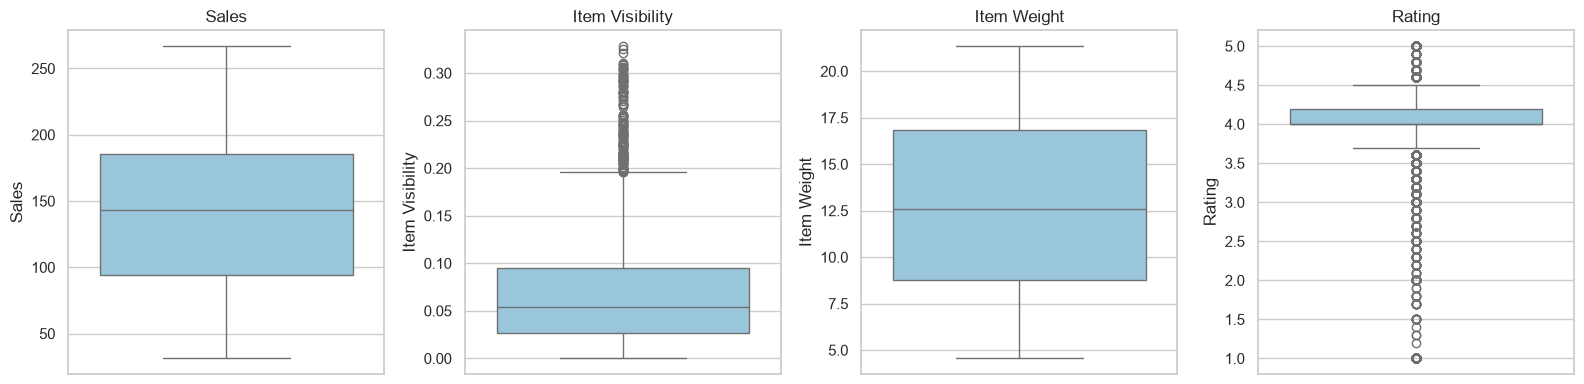

In [7]:
cols = ["Sales", "Item Visibility", "Item Weight", "Rating"]
rows = []
for c in cols:
    s = clean[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < low) | (s > high)).sum()
    rows.append([c, low, high, n, n / len(s) * 100])
outliers = pd.DataFrame(rows, columns=["Column", "Lower limit", "Upper limit", "Outliers", "Percent"])
display(outliers)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(y=clean[c], ax=ax, color="#8ecae6")
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Finding:**
- `Sales` and `Item Weight` have **no** outliers.
- `Item Visibility` has about 144 high values (visibility above about 0.19). These are valid but unusual, so they are kept.
- `Rating` shows many "outliers" only because most ratings are high (around 4-5), so low ratings look unusual. They are real customer scores, so they are kept.

# Objective 1 (continued): Overall sales and rating

### Task 1.3 - 1.4: Key performance indicators

In [8]:
total = clean["Sales"].sum()
print(f"Total sales           : {total:,.2f}")
print(f"Average sales / record: {clean['Sales'].mean():,.2f}")
print(f"Average rating        : {clean['Rating'].mean():.2f} / 5")
print(f"Records               : {len(clean):,}")
print(f"Unique items          : {clean['Item Identifier'].nunique():,}")
print(f"Unique outlets        : {clean['Outlet Identifier'].nunique()}")

Total sales           : 1,201,681.49
Average sales / record: 140.99
Average rating        : 3.97 / 5
Records               : 8,523
Unique items          : 1,559
Unique outlets        : 10


# Objective 3: What drives better sales?

In [9]:
def summarize(col):
    s = clean.groupby(col)["Sales"].agg(Total="sum", Average="mean", Records="count")
    s["Share %"] = s["Total"] / clean["Sales"].sum() * 100
    return s.sort_values("Total", ascending=False)

def bar(s, title, color="#219ebc", col="Total"):
    ax = s[col].sort_values().plot(kind="barh", figsize=(9, max(3, len(s) * 0.4)), color=color)
    ax.set_title(title); ax.set_xlabel("Total Sales"); ax.set_ylabel("")
    plt.tight_layout(); plt.show()

### Task 3.1: Which product types sell more?

,Total,Average,Records,Share %
Item Type,,,,
Fruits and Vegetables,"178,124.08",144.58,1232,14.82
Snack Foods,"175,433.92",146.19,1200,14.60
Household,"135,976.53",149.42,910,11.32
Frozen Foods,"118,558.88",138.50,856,9.87
Dairy,"101,276.46",148.50,682,8.43
Canned,"90,706.73",139.76,649,7.55
Baking Goods,"81,894.74",126.38,648,6.82
Health and Hygiene,"68,025.84",130.82,520,5.66
Meat,"59,449.86",139.88,425,4.95


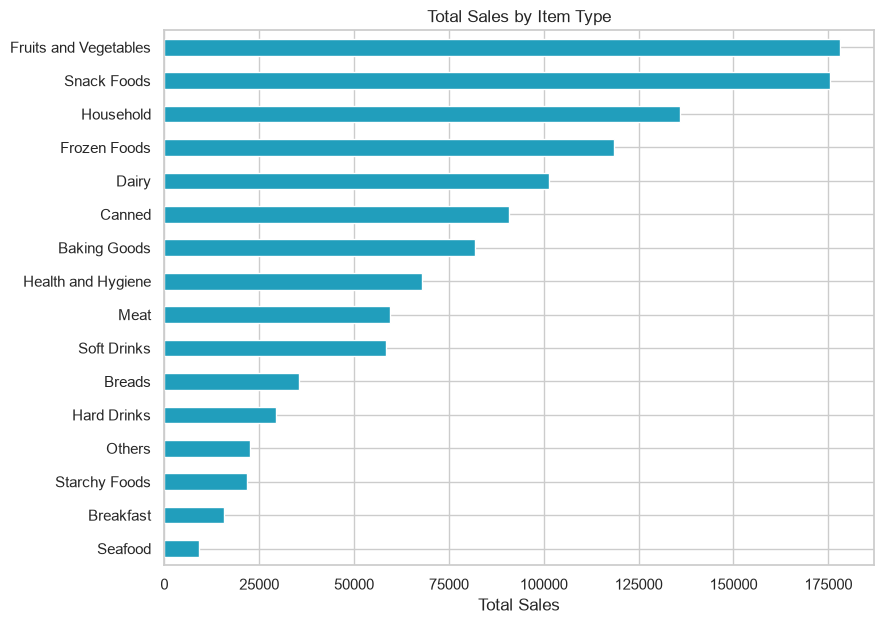

In [10]:
item_sales = summarize("Item Type")
display(item_sales)
bar(item_sales, "Total Sales by Item Type")

### Task 3.2: Which outlets perform better?

,Total,Average,Records,Share %
Outlet Type,,,,
Supermarket Type1,"787,549.89",141.21,5577,65.54
Grocery Store,"151,939.15",140.29,1083,12.64
Supermarket Type2,"131,477.78",141.68,928,10.94
Supermarket Type3,"130,714.67",139.80,935,10.88


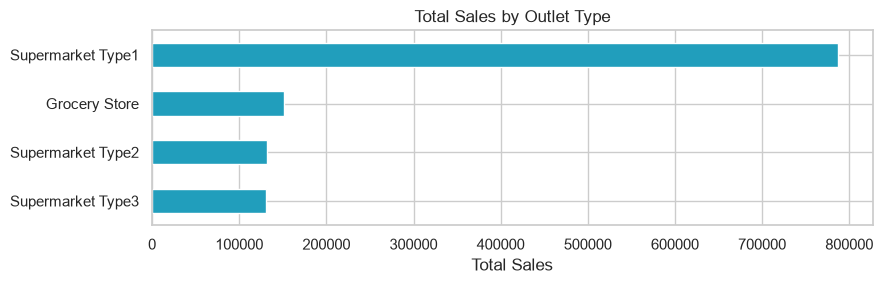

In [11]:
outlet_type = summarize("Outlet Type")
display(outlet_type)
bar(outlet_type, "Total Sales by Outlet Type")

,Total,Average,Records,Share %
Outlet Location Type,,,,
Tier 3,"472,133.03",140.94,3350,39.29
Tier 2,"393,150.65",141.17,2785,32.72
Tier 1,"336,397.81",140.87,2388,27.99


,Total,Average,Records,Share %
Outlet Size,,,,
Medium,"507,895.74",139.88,3631,42.27
Small,"444,794.17",141.70,3139,37.01
High,"248,991.59",142.04,1753,20.72


,Total,Average,Records,Share %
Item Fat Content,,,,
Low Fat,"776,319.69",140.71,5517,64.60
Regular,"425,361.80",141.50,3006,35.40


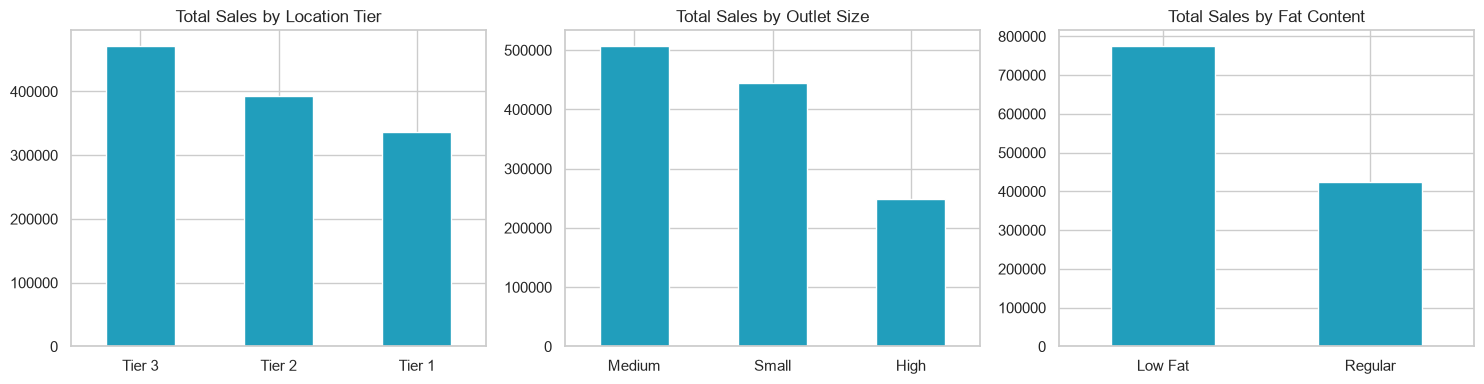

In [12]:
location = summarize("Outlet Location Type")
size = summarize("Outlet Size")
fat = summarize("Item Fat Content")
display(location); display(size); display(fat)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (s, t) in zip(axes, [(location, "Location Tier"), (size, "Outlet Size"), (fat, "Fat Content")]):
    s["Total"].plot(kind="bar", ax=ax, color="#219ebc", rot=0)
    ax.set_title("Total Sales by " + t); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [13]:
outlet_id = clean.groupby("Outlet Identifier").agg(
    Outlet_Type=("Outlet Type", "first"), Size=("Outlet Size", "first"),
    Location=("Outlet Location Type", "first"), Year=("Outlet Establishment Year", "first"),
    Total=("Sales", "sum"), Average=("Sales", "mean"), Records=("Sales", "count")
).sort_values("Total", ascending=False)
display(outlet_id)

,Outlet_Type,Size,Location,Year,Total,Average,Records
Outlet Identifier,,,,,,,
OUT035,Supermarket Type1,Small,Tier 2,2017,"133,103.91",143.12,930
OUT046,Supermarket Type1,Small,Tier 1,2016,"132,113.37",142.06,930
OUT013,Supermarket Type1,High,Tier 3,2014,"131,809.02",141.43,932
OUT018,Supermarket Type2,Medium,Tier 3,2022,"131,477.78",141.68,928
OUT045,Supermarket Type1,Small,Tier 2,2015,"130,942.78",140.95,929
OUT027,Supermarket Type3,Medium,Tier 3,2018,"130,714.67",139.80,935
OUT049,Supermarket Type1,Medium,Tier 1,2012,"130,476.86",140.30,930
OUT017,Supermarket Type1,Small,Tier 2,2020,"129,103.96",139.42,926
OUT010,Grocery Store,Small,Tier 3,2011,"78,131.57",140.78,555


**Important:** Supermarket Type1 has the biggest *total* because it contains **6 of the 10 outlets** (and about 65% of the records). Its *average sale per record* (141.21) is almost the same as every other type (139.80 to 141.68). So bigger total does not mean each sale is bigger; there are simply more of them.

### Task 3.3: Are visibility, weight, rating and outlet features connected with sales?

,Sales,Rating,Item Visibility,Item Weight,Outlet Establishment Year
Sales,1.00,0.01,-0.00,0.03,-0.00
Rating,0.01,1.00,0.00,0.00,0.00
Item Visibility,-0.00,0.00,1.00,-0.01,-0.06
Item Weight,0.03,0.00,-0.01,1.00,-0.00
Outlet Establishment Year,-0.00,0.00,-0.06,-0.00,1.00


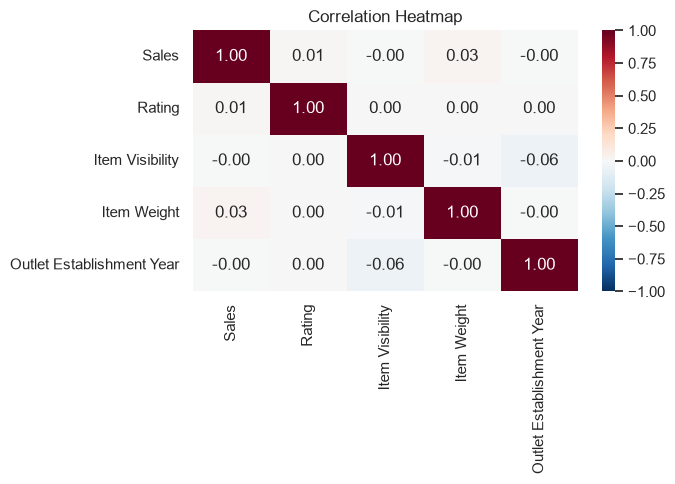

In [14]:
num = clean[["Sales", "Rating", "Item Visibility", "Item Weight", "Outlet Establishment Year"]]
corr = num.corr()
display(corr)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.tight_layout(); plt.show()

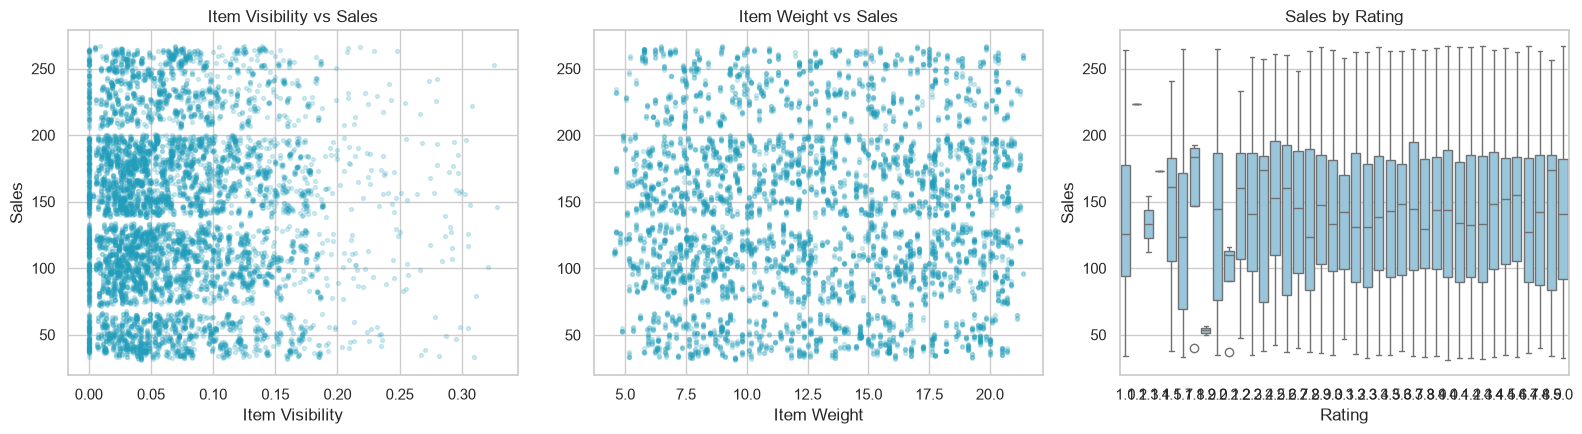

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(clean["Item Visibility"], clean["Sales"], alpha=.2, s=8, color="#219ebc")
axes[0].set_title("Item Visibility vs Sales"); axes[0].set_xlabel("Item Visibility"); axes[0].set_ylabel("Sales")
axes[1].scatter(clean["Item Weight"], clean["Sales"], alpha=.2, s=8, color="#219ebc")
axes[1].set_title("Item Weight vs Sales"); axes[1].set_xlabel("Item Weight")
sns.boxplot(data=clean, x="Rating", y="Sales", ax=axes[2], color="#8ecae6")
axes[2].set_title("Sales by Rating")
plt.tight_layout(); plt.show()

,Total,Average,Records
Outlet Establishment Year,,,
2011,"78,131.57",140.78,555
2012,"130,476.86",140.30,930
2014,"131,809.02",141.43,932
2015,"130,942.78",140.95,929
2016,"132,113.37",142.06,930
2017,"133,103.91",143.12,930
2018,"204,522.26",139.80,1463
2020,"129,103.96",139.42,926
2022,"131,477.78",141.68,928


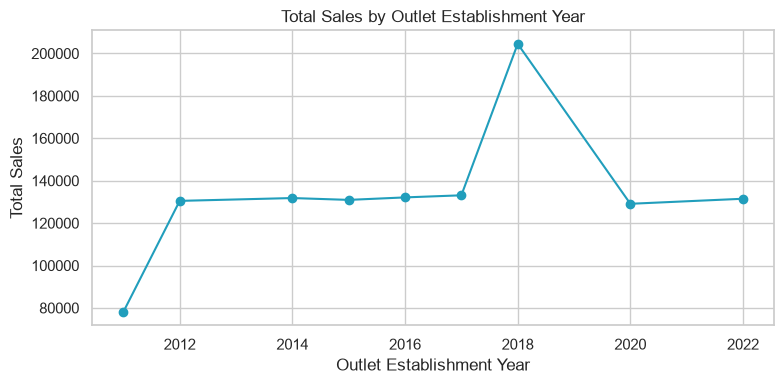

In [16]:
yr = clean.groupby("Outlet Establishment Year")["Sales"].agg(Total="sum", Average="mean", Records="count")
display(yr)
yr["Total"].plot(kind="line", marker="o", figsize=(8, 4), title="Total Sales by Outlet Establishment Year", color="#219ebc")
plt.ylabel("Total Sales"); plt.tight_layout(); plt.show()

**Finding:** all correlations with `Sales` are essentially zero (between -0.00 and 0.03). Visibility, weight, rating and outlet age do **not** explain how much a single item sells in this data. Correlation only shows association, not cause and effect. The 2018 total looks large only because two outlets (OUT019 and OUT027) were both established that year.

### Task 3.4: Better vs lower performing products and outlets

Top 5 item types:


,Total,Average,Records,Share %
Item Type,,,,
Fruits and Vegetables,"178,124.08",144.58,1232,14.82
Snack Foods,"175,433.92",146.19,1200,14.60
Household,"135,976.53",149.42,910,11.32
Frozen Foods,"118,558.88",138.50,856,9.87
Dairy,"101,276.46",148.50,682,8.43


Bottom 5 item types:


,Total,Average,Records,Share %
Item Type,,,,
Hard Drinks,"29,334.68",137.08,214,2.44
Others,"22,451.89",132.85,169,1.87
Starchy Foods,"21,880.03",147.84,148,1.82
Breakfast,"15,596.70",141.79,110,1.30
Seafood,"9,077.87",141.84,64,0.76


Top 5 share of all sales   : 59.0%
Bottom 5 share of all sales: 8.2%


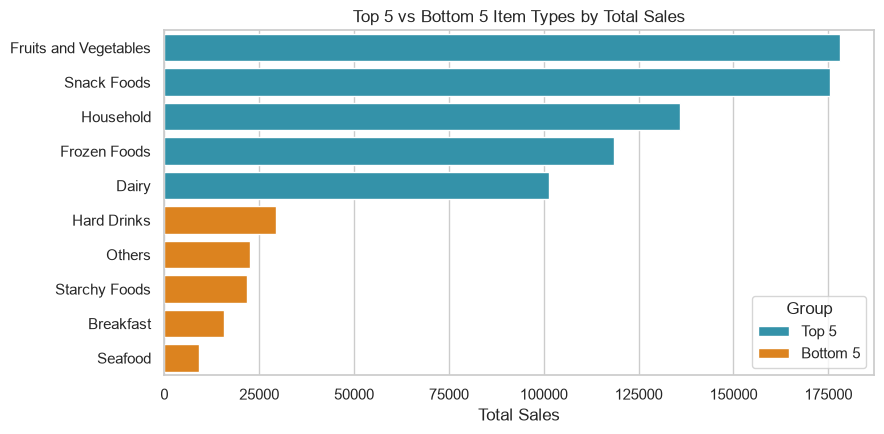

In [17]:
top_n = 5
print("Top 5 item types:");    display(item_sales.head(top_n))
print("Bottom 5 item types:"); display(item_sales.tail(top_n))

compare = pd.concat([item_sales.head(top_n).assign(Group="Top 5"),
                     item_sales.tail(top_n).assign(Group="Bottom 5")])
print("Top 5 share of all sales   : %.1f%%" % item_sales.head(top_n)["Share %"].sum())
print("Bottom 5 share of all sales: %.1f%%" % item_sales.tail(top_n)["Share %"].sum())

plt.figure(figsize=(9, 4.5))
sns.barplot(data=compare.reset_index(), y="Item Type", x="Total", hue="Group",
            palette={"Top 5": "#219ebc", "Bottom 5": "#fb8500"}, dodge=False)
plt.title("Top 5 vs Bottom 5 Item Types by Total Sales"); plt.xlabel("Total Sales"); plt.ylabel("")
plt.tight_layout(); plt.show()

In [18]:
item_id = clean.groupby("Item Identifier")["Sales"].agg(Total="sum", Records="count", Average="mean")
print("Top 5 individual items:");    display(item_id.sort_values("Total", ascending=False).head(5))
print("Bottom 5 individual items:"); display(item_id.sort_values("Total").head(5))

print("Best 3 vs worst 3 outlets:")
display(pd.concat([outlet_id.head(3), outlet_id.tail(3)]))

Top 5 individual items:


,Total,Records,Average
Item Identifier,,,
FDU12,"2,371.01",9,263.45
FDT07,"2,306.90",9,256.32
NCQ06,"2,294.71",9,254.97
FDL58,"2,111.65",8,263.96
NCB31,"2,104.73",8,263.09


Bottom 5 individual items:


,Total,Records,Average
Item Identifier,,,
NCC55,72.87,2,36.43
FDF38,80.23,2,40.11
FDN52,86.92,1,86.92
FDE52,88.95,1,88.95
NCR42,101.07,3,33.69


Best 3 vs worst 3 outlets:


,Outlet_Type,Size,Location,Year,Total,Average,Records
Outlet Identifier,,,,,,,
OUT035,Supermarket Type1,Small,Tier 2,2017,"133,103.91",143.12,930
OUT046,Supermarket Type1,Small,Tier 1,2016,"132,113.37",142.06,930
OUT013,Supermarket Type1,High,Tier 3,2014,"131,809.02",141.43,932
OUT017,Supermarket Type1,Small,Tier 2,2020,"129,103.96",139.42,926
OUT010,Grocery Store,Small,Tier 3,2011,"78,131.57",140.78,555
OUT019,Grocery Store,Small,Tier 1,2018,"73,807.58",139.79,528


**Finding:** the top 5 item types bring in about 59% of all sales, while the bottom 5 bring in under 8%. For outlets, the 8 supermarket outlets each sell about 129,000-133,000, while the two Grocery Stores (OUT010 and OUT019) sell about 74,000-78,000 each. They have roughly **40% fewer records**, but their average sale per record (about 140) is the same.

# Objective 4: Business decisions

### Task 4.1: Products contributing most to sales
- **Fruits and Vegetables** (14.8% of sales) and **Snack Foods** (14.6%) are the two biggest item types, followed by **Household** (11.3%), **Frozen Foods** (9.9%) and **Dairy** (8.4%).
- Together the top 5 types contribute about 59% of total sales.

### Task 4.2: Outlets and locations performing better
- **Supermarket Type1** gives about 65.5% of total sales (6 outlets).
- The strongest single outlets are **OUT035, OUT046 and OUT013** (each about 11% of sales).
- **Tier 3** is the best location (39.3% of sales), then Tier 2 (32.7%) and Tier 1 (28.0%).
- **Medium** outlets give the most sales (42.3%).

### Task 4.3: Where performance can be improved
- **Seafood, Breakfast, Starchy Foods and Others** are the weakest item types (each under 2% of sales). Review pricing, shelf space and range before adding stock.
- **Grocery Stores (OUT010, OUT019)** sell about 40% less in total because they record far fewer sales. Their average sale per record matches the others, so the opportunity is more footfall and more transactions, not higher prices.
- **Baking Goods, Health and Hygiene, Soft Drinks** have the lowest average sale per record (126-131 versus about 141 overall). Bundles or offers could lift this.
- **Tier 1** locations contribute the least total sales (28%). Check why customer volume is lower.
- **Data quality:** `Item Weight` is missing for every record of OUT019 and OUT027. Fix recording at those outlets.

### Task 4.4: Practical suggestions
1. Keep **Fruits and Vegetables, Snack Foods and Household** always in stock. They carry about 41% of sales.
2. Put more effort into **Grocery Stores**: promotions, home delivery and better product range to raise the number of sales.
3. Run bundle offers on low-average categories (Baking Goods, Health and Hygiene, Soft Drinks).
4. Do not rely on shelf visibility alone to raise sales. It shows almost no link with sales here, so test changes in small pilots first.
5. Standardise data entry (fat content labels, item weight) so future analysis is reliable.

### Limits of this analysis
Results are descriptive and show association, not cause and effect. The data has no dates, so trends over time (seasonality) cannot be studied. The data has no cost or profit, so profitability cannot be judged.

In [19]:
# Save the cleaned data
import os
os.makedirs("outputs", exist_ok=True)
clean.to_csv("outputs/blinkit_cleaned_data.csv", index=False)
print("Cleaned data saved to outputs/blinkit_cleaned_data.csv")

Cleaned data saved to outputs/blinkit_cleaned_data.csv
